# Strategy backtesting: figures of Lesson 02.01

- This notebook generates the figures of the slides
  `Lesson02.01_Strategy_Backtesting.smd` from simulated data and closed-form
  curves, and saves them as PNG files
- The pedagogical arc:
  - Backtest mechanics: transaction costs, look-ahead bias, and survivorship
    bias
  - Backtest discipline: backtest overfitting, the false strategy theorem,
    multiple testing, purged cross-validation, and the deflated Sharpe ratio

In [1]:
%load_ext autoreload
%autoreload 2

import logging

In [2]:
import helpers.hintrospection as hintros
import helpers.hmatplotlib as hmatplo
import helpers.hnotebook as hnotebook

import L02_01_strategy_backtesting_utils as utils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

INFO  > /Users/saggese/src/venv/client_venv.helpers/lib/python3.11/site-packages/ipykernel_launcher.py -f /private/var/folders/pd/0_nppqrn3cn7936mmhk37gcw0000gn/T/tmputovnkn_.json --HistoryManager.hist_file=:memory:


In [3]:
# Directory of the figures, and prefix of the markdown reference to paste in the
# slides.
out_dir_name = "figures"
markdown_path_prefix = "book_Modern_AI_for_Finance/lectures_source"

# Figure sizes: a single panel fits a column of a slide, the cross-validation
# timeline needs more width.
figsize = (6.0, 4.0)
figsize_wide = (7.0, 3.0)

# Seed of all the simulations. It is chosen so that the simulated outcomes are
# representative of the average behavior, e.g., the Sharpe ratio of the correct
# backtest on a random walk is close to 0.
seed = 32

# Part 1: Backtest mechanics

## Cell 1.1: Transaction costs and net Sharpe ratio

**Goal**
- Show how the cost per unit traded erodes the Sharpe ratio of a strategy
- See that the breakeven cost is the gross return divided by the annual
  turnover, so a fast strategy tolerates much smaller costs

**Description**
- Inputs
  - `gross_return`: annual return before costs
  - `volatility`: annual volatility of the strategy
  - `turnovers`: annual turnover of each rebalancing frequency
  - `max_cost_bps`: largest cost per unit traded, in basis points
  - `figsize`: size of the figure, as (width, height) in inches

- Panels
  - `Net Sharpe`: one line per rebalancing frequency, with a dot at the
    breakeven cost where the net Sharpe ratio is 0

Saved figure to 'figures/L02.01.Cost_Sensitivity.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L02.01.Cost_Sensitivity.png)


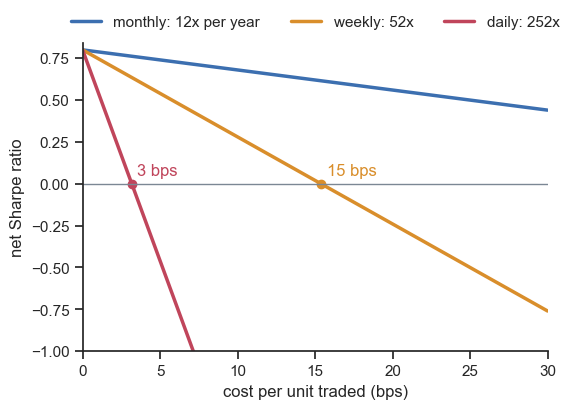

In [4]:
# Plot the net Sharpe ratio against the cost per unit traded.
turnovers = {
    "monthly: 12x per year": 12.0,
    "weekly: 52x": 52.0,
    "daily: 252x": 252.0,
}
fig = utils.cell1_1_plot_cost_sensitivity(
    gross_return=0.08,
    volatility=0.10,
    turnovers=turnovers,
    max_cost_bps=30.0,
    figsize=figsize,
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L02.01.Cost_Sensitivity.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Change `gross_return` from 0.08 to 0.04
  - Observe the breakeven cost halve: from 15 to 8 bps for the weekly
    strategy and from 3 to 2 bps for the daily strategy

**Implementation** `cell1_1_plot_cost_sensitivity()`
- Computes the annual cost as turnover times cost per unit traded
- Divides the net return by the volatility to get the net Sharpe ratio
- Marks the breakeven cost `gross_return / turnover` when it fits the x axis

In [5]:
hintros.print_obj_info(utils.cell1_1_plot_cost_sensitivity)

- `cell1_1_plot_cost_sensitivity(*, gross_return: float, volatility: float, turnovers: Dict[str, float], max_cost_bps: float, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot the net Sharpe ratio against the cost per unit traded.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L02_strategy_backtesting/L02_01_strategy_backtesting_utils.py#L161


## Cell 1.2: Look-ahead bias

**Goal**
- Backtest a trend rule on a random walk, which has no signal by
  construction
- See that a one-bar look-ahead bug turns a worthless rule into a
  spectacular backtest

**Description**
- Inputs
  - `n_days`: number of simulated days
  - `volatility`: daily volatility of the returns
  - `window`: number of days of the moving average
  - `seed`: seed of the random number generator

- Panels
  - `Cumulative PnL`: correct backtest in blue, which trades the day after the
    signal, and biased backtest in red, which earns the return of the same day
    that the signal used

Saved figure to 'figures/L02.01.Look_Ahead_Bias.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L02.01.Look_Ahead_Bias.png)


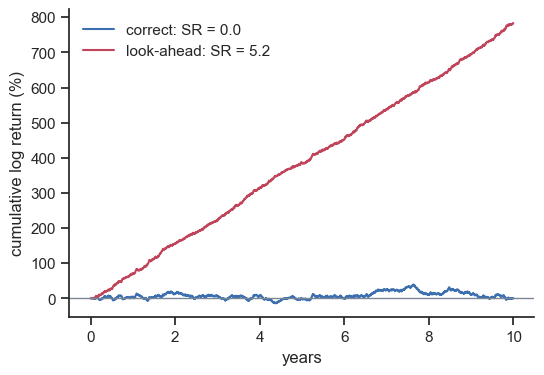

In [6]:
# Plot the correct and the look-ahead backtest of a moving-average rule.
fig = utils.cell1_2_plot_look_ahead_bias(
    n_days=2520, volatility=0.01, window=20, seed=seed, figsize=figsize
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L02.01.Look_Ahead_Bias.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Change `window` from 20 to 5
  - Observe the Sharpe ratio of the biased backtest rise from 5.2 to about
    11.6, since today's return is a larger part of a short moving average
- Change `window` from 20 to 250
  - Observe the biased Sharpe ratio fall to 1.7: a small leak still produces a
    Sharpe ratio that looks excellent

**Implementation** `cell1_2_plot_look_ahead_bias()`
- Simulates IID Gaussian daily returns and their cumulative sum as log price
- Sets the position to the sign of the log price minus its moving average,
  computed with the close of the current day
- Multiplies the position by the return of the next day (correct) or of the
  same day (look-ahead)

In [7]:
hintros.print_obj_info(utils.cell1_2_plot_look_ahead_bias)

- `cell1_2_plot_look_ahead_bias(*, n_days: int, volatility: float, window: int, seed: int, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot a trend rule on a random walk with and without a one-bar look-ahead.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L02_strategy_backtesting/L02_01_strategy_backtesting_utils.py#L223


## Cell 1.3: Survivorship bias

**Goal**
- Backtest a strategy that buys last month's worst stocks on a simulated
  universe in which falling stocks delist
- See that a database of today's survivors inflates the backtest, because
  it drops exactly the losers that went bankrupt

**Description**
- Inputs
  - `n_stocks`: number of stocks in the universe
  - `n_months`: number of months
  - `mean_return`: mean monthly log return of every stock
  - `volatility`: monthly volatility of the log returns
  - `delisting_price`: price, relative to the start, that triggers a
    delisting
  - `delisting_return`: extra return in the delisting month
  - `quantile`: fraction of the listed stocks bought each month
  - `seed`: seed of the random number generator

- Panels
  - `Equity`: equity curve of the strategy on the full universe in blue and on
    the survivors only in red, with the annualized return in the legend

Saved figure to 'figures/L02.01.Survivorship_Bias.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L02.01.Survivorship_Bias.png)


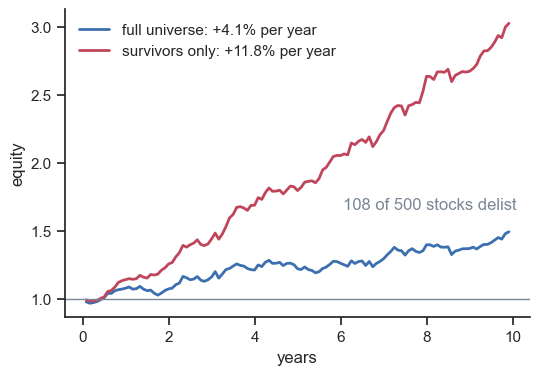

In [8]:
# Plot the buy-the-losers backtest on the full universe and on the survivors.
fig = utils.cell1_3_plot_survivorship_bias(
    n_stocks=500,
    n_months=120,
    mean_return=0.001,
    volatility=0.10,
    delisting_price=0.3,
    delisting_return=-0.3,
    quantile=0.1,
    seed=seed,
    figsize=figsize,
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L02.01.Survivorship_Bias.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Change `delisting_return` from -0.3 to 0
  - Observe the full-universe return rise from 4.1% to 6.2% per year, while
    the survivor-only return stays at 11.8%: most of the bias comes from
    dropping the delisted stocks, not from their last loss
- Change `volatility` from 0.10 to 0.05
  - Observe only 6 stocks delist and the two backtests agree within 0.1% per
    year

**Implementation** `cell1_3_plot_survivorship_bias()`
- Simulates Gaussian monthly log returns and delists a stock the first month
  its price falls below `delisting_price`
- Keeps in the survivor-only universe the stocks listed in the last month
- Each month, buys with equal weights the `quantile` of listed stocks with
  the worst return of the previous month

In [9]:
hintros.print_obj_info(utils.cell1_3_plot_survivorship_bias)

- `cell1_3_plot_survivorship_bias(*, n_stocks: int, n_months: int, mean_return: float, volatility: float, delisting_price: float, delisting_return: float, quantile: float, seed: int, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot a buy-the-losers backtest on the full universe and on survivors.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L02_strategy_backtesting/L02_01_strategy_backtesting_utils.py#L346


# Part 2: Backtest discipline

## Cell 2.1: In-sample vs. out-of-sample Sharpe ratio

**Goal**
- Select the best of 200 strategies that have no skill by construction
- See that the in-sample winner has an excellent Sharpe ratio and an
  out-of-sample Sharpe ratio close to 0

**Description**
- Inputs
  - `n_strategies`: number of strategies, all with true Sharpe ratio 0
  - `n_days_is`: number of in-sample days
  - `n_days_oos`: number of out-of-sample days
  - `volatility`: daily volatility of the strategy returns
  - `seed`: seed of the random number generator

- Panels
  - `Scatter`: out-of-sample against in-sample annualized Sharpe ratio, with
    the strategy selected in-sample in red

Saved figure to 'figures/L02.01.IS_vs_OOS_Sharpe.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L02.01.IS_vs_OOS_Sharpe.png)


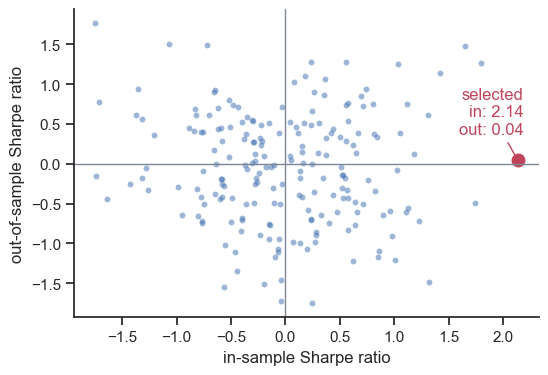

In [10]:
# Plot in-sample against out-of-sample Sharpe ratio of zero-skill strategies.
fig = utils.cell2_1_plot_is_vs_oos_sharpe(
    n_strategies=200,
    n_days_is=504,
    n_days_oos=504,
    volatility=0.01,
    seed=seed,
    figsize=figsize,
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L02.01.IS_vs_OOS_Sharpe.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Change `n_days_is` from 504 to 2520
  - Observe the selected in-sample Sharpe ratio fall from 2.14 to 1.02: a
    longer backtest makes each estimate less noisy, so luck inflates the
    maximum less

**Implementation** `cell2_1_plot_is_vs_oos_sharpe()`
- Simulates IID Gaussian daily returns with mean 0 for each strategy
- Computes the annualized Sharpe ratio on the in-sample and on the
  out-of-sample days
- Selects the strategy with the largest in-sample Sharpe ratio

In [11]:
hintros.print_obj_info(utils.cell2_1_plot_is_vs_oos_sharpe)

- `cell2_1_plot_is_vs_oos_sharpe(*, n_strategies: int, n_days_is: int, n_days_oos: int, volatility: float, seed: int, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot in-sample against out-of-sample Sharpe ratio of zero-skill strategies.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L02_strategy_backtesting/L02_01_strategy_backtesting_utils.py#L420


## Cell 2.2: Expected maximum Sharpe ratio

**Goal**
- Plot the expected maximum Sharpe ratio of $N$ zero-skill trials given by
  the false strategy theorem
- Check the formula with a Monte Carlo simulation

**Description**
- Inputs
  - `n_years`: length of each backtest in years
  - `trial_grid`: numbers of trials of the Monte Carlo points
  - `n_sims`: number of Monte Carlo repetitions per number of trials
  - `seed`: seed of the random number generator

- Panels
  - `Expected maximum`: closed-form curve in blue and Monte Carlo means in red,
    against the number of trials on a log scale

Saved figure to 'figures/L02.01.Expected_Max_Sharpe.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L02.01.Expected_Max_Sharpe.png)


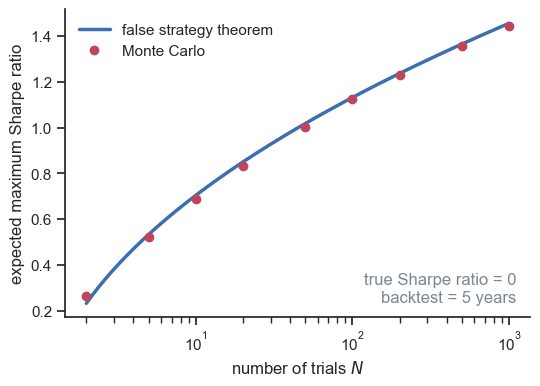

In [12]:
# Plot the expected maximum Sharpe ratio against the number of trials.
fig = utils.cell2_2_plot_expected_max_sharpe(
    n_years=5.0,
    trial_grid=[2, 5, 10, 20, 50, 100, 200, 500, 1000],
    n_sims=2000,
    seed=seed,
    figsize=figsize,
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L02.01.Expected_Max_Sharpe.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Change `n_years` from 5 to 20
  - Observe the whole curve halve, e.g., from 1.13 to 0.57 at $N = 100$,
    since the noise of a Sharpe ratio estimate falls as $1 / \sqrt{years}$

**Implementation** `cell2_2_plot_expected_max_sharpe()`
- Sets the standard deviation of an annualized Sharpe ratio estimate to
  $1 / \sqrt{years}$
- Evaluates the false strategy theorem with `expected_max_sharpe()`
- Draws Gaussian Sharpe ratio estimates and averages their maximum over
  `n_sims` repetitions

In [13]:
hintros.print_obj_info(utils.cell2_2_plot_expected_max_sharpe)

- `cell2_2_plot_expected_max_sharpe(*, n_years: float, trial_grid: List[int], n_sims: int, seed: int, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot the expected maximum Sharpe ratio of zero-skill trials.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L02_strategy_backtesting/L02_01_strategy_backtesting_utils.py#L495


## Cell 2.3: Bonferroni and Benjamini-Hochberg

**Goal**
- Compare no correction, Bonferroni, and Benjamini-Hochberg on 100
  strategies, 10 of which have skill
- See that Bonferroni misses true signals, while Benjamini-Hochberg keeps
  most of them with few false discoveries

**Description**
- Inputs
  - `n_null`: number of strategies with no skill
  - `n_true`: number of strategies with skill
  - `true_t_mean`: mean t-statistic of a strategy with skill
  - `alpha`: target FWER for Bonferroni and target FDR for Benjamini-Hochberg
  - `seed`: seed of the random number generator

- Panels
  - `Sorted p-values`: true signals in green and no-skill strategies in gray,
    with the uncorrected threshold, the Bonferroni line, and the
    Benjamini-Hochberg line

Saved figure to 'figures/L02.01.BH_Procedure.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L02.01.BH_Procedure.png)


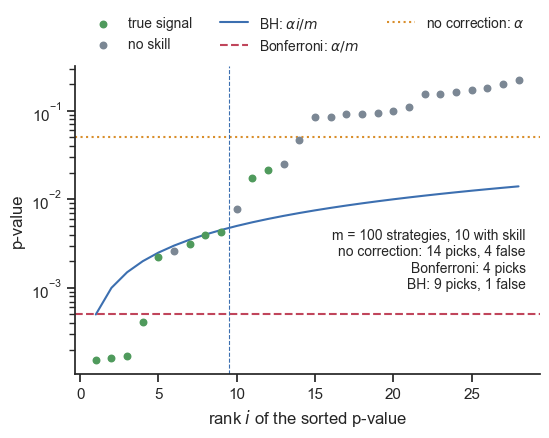

In [14]:
# Plot sorted p-values against the multiple-testing thresholds.
fig = utils.cell2_3_plot_bh_procedure(
    n_null=90,
    n_true=10,
    true_t_mean=3.0,
    alpha=0.05,
    seed=seed,
    figsize=figsize,
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L02.01.BH_Procedure.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Change `true_t_mean` from 3 to 4
  - Observe Bonferroni pick 8 strategies instead of 4 and Benjamini-Hochberg
    pick 11, of which 1 is false
- Change `alpha` from 0.05 to 0.10
  - Observe the uncorrected test pick 20 strategies, half of them false

**Implementation** `cell2_3_plot_bh_procedure()`
- Draws t-statistics from $N(0, 1)$ for no skill and from
  $N(t_{mean}, 1)$ for skill, and converts them to one-sided p-values
- Sorts the p-values and finds the largest rank $i$ with
  $p_{(i)} \le \alpha i / m$
- Counts the picks and the false picks of each procedure

In [15]:
hintros.print_obj_info(utils.cell2_3_plot_bh_procedure)

- `cell2_3_plot_bh_procedure(*, n_null: int, n_true: int, true_t_mean: float, alpha: float, seed: int, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot sorted p-values against the Bonferroni and Benjamini-Hochberg lines.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L02_strategy_backtesting/L02_01_strategy_backtesting_utils.py#L563


## Cell 2.4: Purged and embargoed k-fold cross-validation

**Goal**
- Show which observations each fold uses to train and to test
- See that purging removes the training labels that overlap the test labels,
  and the embargo removes the next observations as well

**Description**
- Inputs
  - `n_obs`: number of observations
  - `n_folds`: number of folds
  - `label_horizon`: number of observations spanned by one label
  - `embargo`: number of observations embargoed after the test block
  - `figsize`: size of the figure, as (width, height) in inches

- Panels
  - `Folds`: one row per fold, with train in blue, test in orange, purged in
    gray, and embargoed in red

Saved figure to 'figures/L02.01.Purged_KFold.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L02.01.Purged_KFold.png)


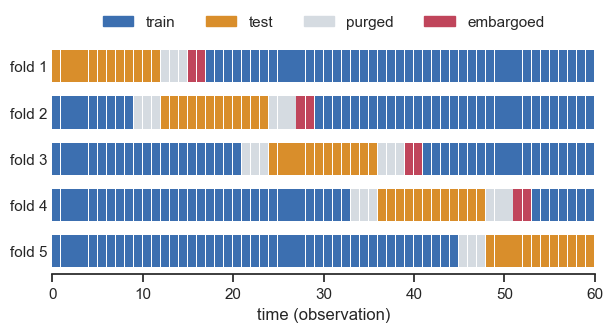

In [16]:
# Plot the purged and embargoed k-fold splits.
fig = utils.cell2_4_plot_purged_kfold(
    n_obs=60,
    n_folds=5,
    label_horizon=3,
    embargo=2,
    figsize=figsize_wide,
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L02.01.Purged_KFold.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Change `label_horizon` from 3 to 6
  - Observe the purged zones double on each side of the test block: longer
    labels overlap more training observations

**Implementation** `cell2_4_plot_purged_kfold()`
- Splits the observations into `n_folds` contiguous test blocks
- Purges the `label_horizon` training observations before and after each test
  block
- Embargoes the next `embargo` observations after the purged ones

In [17]:
hintros.print_obj_info(utils.cell2_4_plot_purged_kfold)

- `cell2_4_plot_purged_kfold(*, n_obs: int, n_folds: int, label_horizon: int, embargo: int, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot the train, test, purged, and embargoed observations of each fold.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L02_strategy_backtesting/L02_01_strategy_backtesting_utils.py#L705


## Cell 2.5: Deflated Sharpe ratio

**Goal**
- Plot the deflated Sharpe ratio of a selected strategy against the number of
  trials behind it
- See how many trials make a backtest with a given Sharpe ratio
  insignificant

**Description**
- Inputs
  - `annual_sharpes`: observed annualized Sharpe ratios, one curve each
  - `n_years`: length of the backtest in years of daily returns
  - `skew`: skewness of the daily returns
  - `kurtosis`: kurtosis of the daily returns
  - `max_trials`: largest number of trials
  - `threshold`: confidence level of the dashed line

- Panels
  - `DSR`: one curve per Sharpe ratio, with a dot where it falls below the
    threshold

Saved figure to 'figures/L02.01.Deflated_Sharpe.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L02.01.Deflated_Sharpe.png)


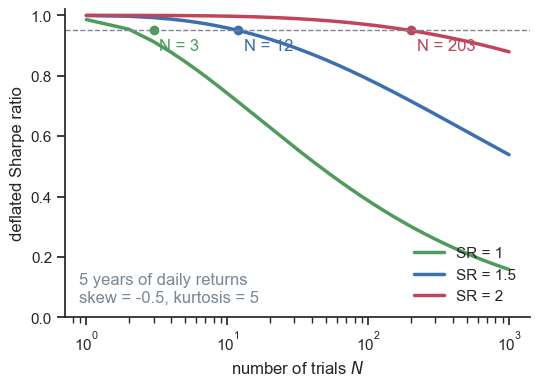

In [18]:
# Plot the deflated Sharpe ratio against the number of trials.
fig = utils.cell2_5_plot_deflated_sharpe(
    annual_sharpes=[1.0, 1.5, 2.0],
    n_years=5.0,
    skew=-0.5,
    kurtosis=5.0,
    max_trials=1000,
    threshold=0.95,
    figsize=figsize,
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L02.01.Deflated_Sharpe.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Change `n_years` from 5 to 10
  - Observe the Sharpe ratio of 1.5 stay significant up to about 500 trials
    instead of 12
- Change `skew` to -2 and `kurtosis` to 10
  - Observe the Sharpe ratio of 1.5 lose significance at 10 trials instead of
    12: negative skew and fat tails widen the error of the estimate

**Implementation** `cell2_5_plot_deflated_sharpe()`
- Converts the annual Sharpe ratio to a daily one
- Sets the benchmark to the expected maximum Sharpe ratio of zero-skill
  trials with `expected_max_sharpe()`
- Evaluates the probabilistic Sharpe ratio against the benchmark with
  `deflated_sharpe()`

In [19]:
hintros.print_obj_info(utils.cell2_5_plot_deflated_sharpe)

- `cell2_5_plot_deflated_sharpe(*, annual_sharpes: List[float], n_years: float, skew: float, kurtosis: float, max_trials: int, threshold: float, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot the deflated Sharpe ratio against the number of trials.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L02_strategy_backtesting/L02_01_strategy_backtesting_utils.py#L768
